# Quantization and matched-use source/channel transmission

Finite digital coding is not automatically better than analog transmission. A meaningful comparison fixes channel uses and power, centers the nonzero source mean, and distinguishes ML from prior-aware estimation.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.quantization import lloyd_max, encode, decode

rng = np.random.default_rng(41)
training = rng.normal(1, np.sqrt(3), 4096)
test = rng.normal(1, np.sqrt(3), 1024)
centers, fit = lloyd_max(training, 16, 1, 3)
stream = encode(test, centers)
restored = decode(stream)
print(
    "Held-out distortion",
    np.mean((test - restored) ** 2),
    "complete bits/sample",
    8 * len(stream) / len(test),
    "training converged",
    fit["converged"],
)

Held-out distortion 0.024999376720225893 complete bits/sample 13.0 training converged True


**Recorded configuration**

{
  "family": "quantization",
  "id": "lloyd_max_16",
  "method": "lloyd_max",
  "levels": 16,
  "mean": 1,
  "variance": 3,
  "train_size": 8192,
  "test_size": 8192
}
{
  "distortion": 0.031302769782237276,
  "entropy_bits": 3.8095790784332335,
  "payload_bits_per_sample": 3.858154296875,
  "container_bits_per_sample": 5.005859375,
  "gaussian_lower_rate_bits": 3.2912641864085344,
  "encoded_bytes": 5126,
  "fit_iterations": 134,
  "fit_converged": true,
  "scope": "Uniform prior-based or training-only Lloyd\u2013Max fixed-level scalar quantizer. Independent test draws; Huffman index frequencies and all float64 reconstruction centers are transmitted. An asymptotic Gaussian R(D) curve is a limit, not the measured rate of this finite scalar codec."
}


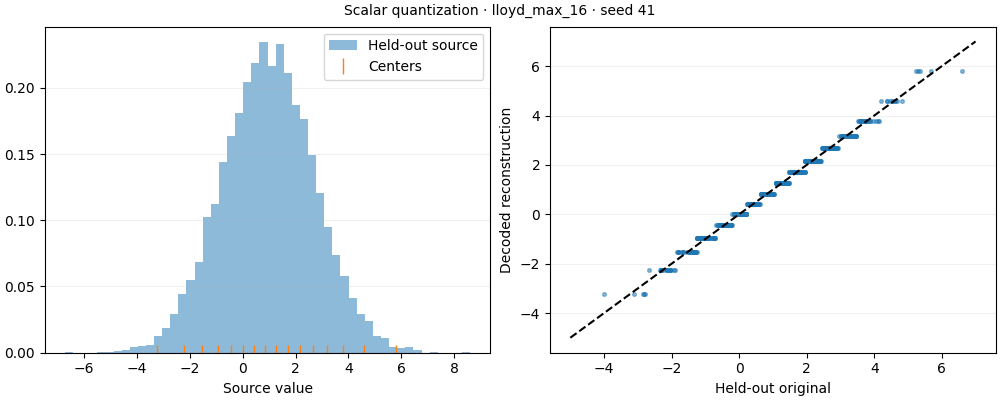

In [3]:
record, path = query("quantization", method="lloyd_max", levels=16)[0]
measured(record)
preview(record)

Four quantization bits use seven Hamming-coded channel uses. Analog repetition gets the same seven uses at expected power one per use. The known Gaussian prior supplies MAP bin probabilities and exact posterior conditional means; these are not fitted to the test source.

**Recorded configuration**

{
  "family": "source_channel",
  "id": "hamming_4_0",
  "quantizer_bits": 4,
  "mean": 1,
  "variance": 3,
  "samples": 4096,
  "snr_db": 0
}
{
  "channel_uses_per_source": 7,
  "source_symbols_per_use": 0.14285714285714285,
  "digital_mse": 3.844616704852412,
  "analog_mse": 0.3748102520964054,
  "digital_map_mse": 1.3720034071005545,
  "digital_mmse_mse": 1.0424928217202598,
  "analog_theoretical_mse": 0.375,
  "ideal_separation_distortion": 0.0234375,
  "quantization_only_mse": 0.06362904835579651,
  "source_clipping_fraction": 0.0,
  "digital_power_per_use": 1.0,
  "analog_observed_power_per_use": 0.986057136141484,
  "scope": "Same channel uses/source and expected power/use, AWGN variance=1/SNR. Compare soft-ML Hamming, source-prior MAP, exact source-prior posterior mean, and repeated analog MMSE. Gaussian bin probabilities/conditional means are known-prior quantities, not fitted to test data. Ideal separation is an asymptotic Gaussian-input bound, not an achieved finite-code rat

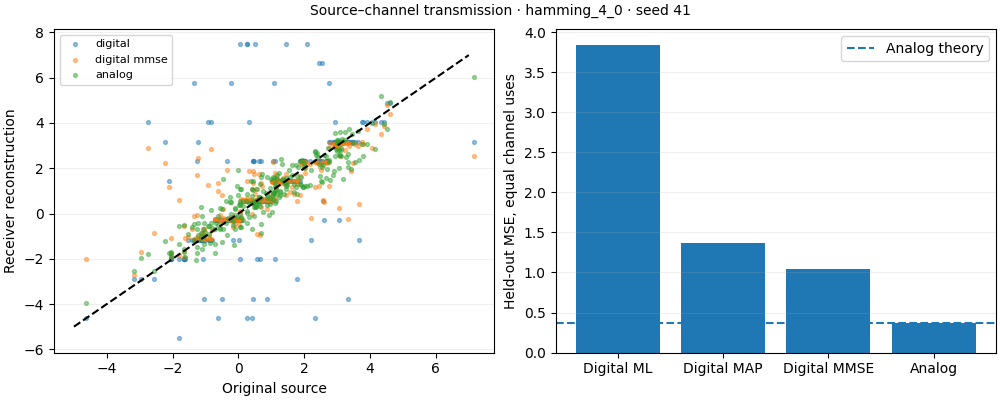

In [4]:
record, path = query("source_channel", quantizer_bits=4, snr_db=0)[0]
measured(record)
preview(record)

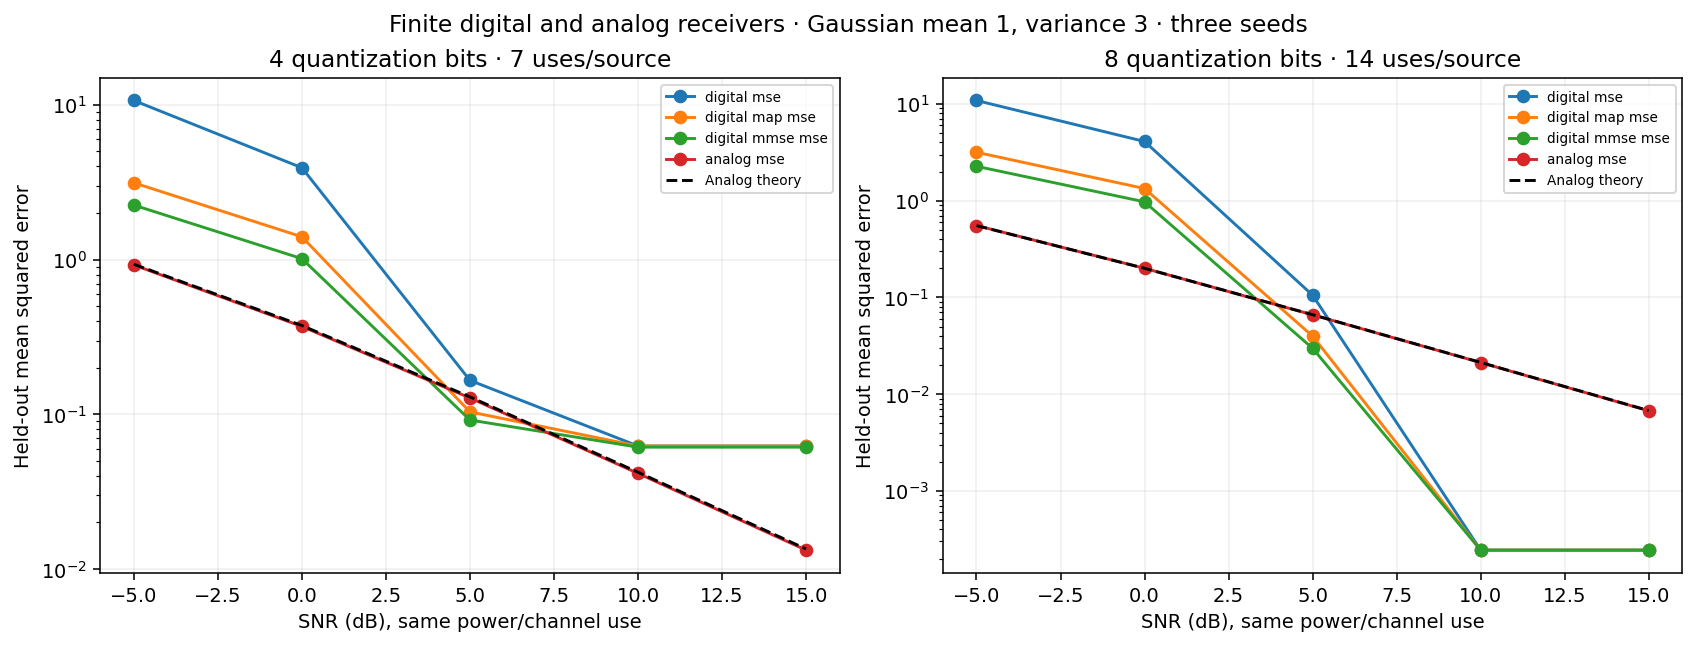

In [5]:
display(Image(filename=str(ROOT / "assets/previews/source_channel_comparison.png")))

The ideal separation distortion is an asymptotic Gaussian-input limit. Short BPSK/Hamming codes do not achieve it. Analog observed power, clipping, quantization-only distortion and receiver-specific MSE are saved, so performance cannot be improved by silently changing the budget.